In [23]:
import pickle
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

# ──────────────── 1. 数据解析辅助函数 ────────────────
def load_fold_data_from_5fold_pkl(pkl_path):
    """从 5fold_results.pkl 中精准提取 fold_results 字典"""
    try:
        data = torch.load(pkl_path, map_location='cpu', weights_only=False)
    except Exception:
        with open(pkl_path, 'rb') as f:
            data = pickle.load(f)

    # 提取核心预测字段
    if isinstance(data, dict) and 'fold_results' in data:
        return data['fold_results']
    return data

def to_numpy(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    return np.asarray(x)

# ──────────────── 2. 5 折插值对齐计算 ────────────────
def compute_5fold_mean_roc(fold_dict):
    mean_fpr = np.linspace(0, 1, 100)
    tprs = []
    aucs = []

    for fold_idx in sorted(fold_dict.keys()):
        labels, probs, _ = fold_dict[fold_idx]
        y_true = to_numpy(labels).ravel()
        y_prob = to_numpy(probs).ravel()

        fpr, tpr, _ = roc_curve(y_true, y_prob)
        # 插值到统一步长网格
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        aucs.append(auc(fpr, tpr))

    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    std_tpr = np.std(tprs, axis=0)
    return mean_fpr, mean_tpr, std_tpr, np.mean(aucs), np.std(aucs)

def compute_5fold_mean_pr(fold_dict):
    mean_recall = np.linspace(0, 1, 100)
    precisions = []
    aps = []

    for fold_idx in sorted(fold_dict.keys()):
        labels, probs, _ = fold_dict[fold_idx]
        y_true = to_numpy(labels).ravel()
        y_prob = to_numpy(probs).ravel()

        prec, rec, _ = precision_recall_curve(y_true, y_prob)
        # precision_recall_curve 返回的 recall 是严格降序，np.interp 要求横坐标升序
        interp_prec = np.interp(mean_recall, rec[::-1], prec[::-1])
        precisions.append(interp_prec)
        aps.append(average_precision_score(y_true, y_prob))

    mean_prec = np.mean(precisions, axis=0)
    std_prec = np.std(precisions, axis=0)
    return mean_recall, mean_prec, std_prec, np.mean(aps), np.std(aps)

# 绘图

In [32]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score

# 1. 扩充主色列表（至少3个颜色：蓝、粉红、绿/橙）
MODEL_COLORS = ['#E28491', '#4A90E2', '#2ECC71', '#F39C12']


def plot_roc_curves_multi(results_list, save_path='roc_multi.svg', model_colors=None):
    """
    在同一张图内绘制多个模型（如 3 个模型）的 5-Fold ROC 曲线
    """
    if model_colors is None:
        model_colors = MODEL_COLORS

    fig, ax = plt.subplots(figsize=(6.2, 5.5))
    mean_fpr = np.linspace(0, 1, 100)

    # 备用线型：除了 Ours 用实线，其余基线模型轮流用不同线型区分
    baseline_linestyles = ['--', '-.', ':']

    # 遍历每个模型（如果有 3 个模型，循环走 3 次）
    for m_idx, res in enumerate(results_list):
        model_name = res.get('model_name', f'Model {m_idx+1}')
        fold_results = res['fold_results']
        main_color = model_colors[m_idx % len(model_colors)]

        tprs = []
        fold_aucs = []

        # 1. 逐折计算 ROC 并插值
        for fold_idx, (labels, probs, *_) in fold_results.items():
            fpr, tpr, _ = roc_curve(labels, probs)
            auc = roc_auc_score(labels, probs)
            fold_aucs.append(auc)

            interp_tpr = np.interp(mean_fpr, fpr, tpr)
            interp_tpr[0] = 0.0
            tprs.append(interp_tpr)

        # 2. 计算均值与标准差
        mean_tpr = np.mean(tprs, axis=0)
        mean_tpr[-1] = 1.0
        mean_auc = np.mean(fold_aucs)
        std_auc = np.std(fold_aucs)

        # 3. 动态配置样式（不再写死只有两个模型）
        is_ours = (model_name == 'MedicalGMU')
        if is_ours:
            linestyle = '-'
            lw = 2.4
            display_name = 'Ours'
        else:
            linestyle = baseline_linestyles[m_idx % len(baseline_linestyles)]
            lw = 1.8
            display_name = model_name

        # 绘制该模型的均值曲线
        ax.plot(
            mean_fpr, mean_tpr,
            color=main_color,
            lw=lw,
            linestyle=linestyle,
            label=f'{display_name} (AUC = {mean_auc:.3f} ± {std_auc:.3f})'
        )

        # 绘制阴影置信区间
        std_tpr = np.std(tprs, axis=0)
        tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
        tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
        ax.fill_between(mean_fpr, tprs_lower, tprs_upper, color=main_color, alpha=0.12)

    # 4. 对角线与格式美化
    ax.plot([0, 1], [0, 1], linestyle=':', color='#7F8C8D', lw=1.0)

    ax.set_xlim([-0.02, 1.02])
    ax.set_ylim([-0.02, 1.02])
    ax.set_xlabel('False Positive Rate', fontsize=12, fontweight='bold', labelpad=8)
    ax.set_ylabel('True Positive Rate', fontsize=12, fontweight='bold', labelpad=8)

    ax.tick_params(axis='both', which='major', labelsize=10, width=1.0)
    ax.grid(True, linestyle=':', alpha=0.35)
    ax.legend(loc='lower right', fontsize=8.8, frameon=True, edgecolor='#E0E0E0', facecolor='white')

    plt.tight_layout()
    plt.savefig(save_path, format='svg', bbox_inches='tight')
    plt.show()
    print(f"Saved multi-model ROC to {save_path}")

In [33]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve, average_precision_score

# 保持与 ROC 一致的主色列表
MODEL_COLORS = ['#E28491', '#4A90E2', '#2ECC71', '#F39C12']


def plot_pr_curves_multi(results_list, save_path='pr_multi.svg', model_colors=None):
    """
    在同一张图内绘制多个模型的 5-Fold PR (Precision-Recall) 曲线
    """
    if model_colors is None:
        model_colors = MODEL_COLORS

    fig, ax = plt.subplots(figsize=(6.2, 5.5))
    mean_recall = np.linspace(0, 1, 100)

    # 备用线型：除了 Ours 用实线，其余基线模型轮流用不同线型区分
    baseline_linestyles = ['--', '-.', ':']

    # 遍历每个模型
    for m_idx, res in enumerate(results_list):
        model_name = res.get('model_name', f'Model {m_idx+1}')
        fold_results = res['fold_results']
        main_color = model_colors[m_idx % len(model_colors)]

        precisions = []
        fold_aps = []

        # 1. 逐折计算 PR 并插值
        for fold_idx, (labels, probs, *_) in fold_results.items():
            # 确保转为 1D 数组
            y_true = np.asarray(labels).ravel()
            y_prob = np.asarray(probs).ravel()

            prec, rec, _ = precision_recall_curve(y_true, y_prob)
            ap = average_precision_score(y_true, y_prob)
            fold_aps.append(ap)

            # 注意：precision_recall_curve 返回的 recall 是降序排列的
            # np.interp 要求横坐标严格单调递增，因此需要翻转 [::-1]
            interp_prec = np.interp(mean_recall, rec[::-1], prec[::-1])
            precisions.append(interp_prec)

        # 2. 计算均值与标准差
        mean_prec = np.mean(precisions, axis=0)
        mean_ap = np.mean(fold_aps)
        std_ap = np.std(fold_aps)

        # 3. 动态配置样式（与 ROC 保持统一视觉语言）
        is_ours = (model_name == 'MedicalGMU')
        if is_ours:
            linestyle = '-'
            lw = 2.4
            display_name = 'Ours'
        else:
            linestyle = baseline_linestyles[m_idx % len(baseline_linestyles)]
            lw = 1.8
            display_name = model_name

        # 绘制该模型的均值曲线
        ax.plot(
            mean_recall, mean_prec,
            color=main_color,
            lw=lw,
            linestyle=linestyle,
            label=f'{display_name} (PR-AUC = {mean_ap:.3f} ± {std_ap:.3f})'
        )

        # 绘制阴影置信区间
        std_prec = np.std(precisions, axis=0)
        prec_upper = np.minimum(mean_prec + std_prec, 1)
        prec_lower = np.maximum(mean_prec - std_prec, 0)
        ax.fill_between(mean_recall, prec_lower, prec_upper, color=main_color, alpha=0.12)

    # 4. 坐标轴与格式美化
    ax.set_xlim([-0.02, 1.02])
    ax.set_ylim([-0.02, 1.02])
    ax.set_xlabel('Recall', fontsize=12, fontweight='bold', labelpad=8)
    ax.set_ylabel('Precision', fontsize=12, fontweight='bold', labelpad=8)

    ax.tick_params(axis='both', which='major', labelsize=10, width=1.0)
    ax.grid(True, linestyle=':', alpha=0.35)
    # PR 曲线通常从左上到右下延伸，图例放置在左下角 (lower left) 避免遮挡曲线
    ax.legend(loc='lower left', fontsize=8.8, frameon=True, edgecolor='#E0E0E0', facecolor='white')

    plt.tight_layout()
    plt.savefig(save_path, format='svg', bbox_inches='tight')
    plt.show()
    print(f"Saved multi-model PR to {save_path}")

## 运行

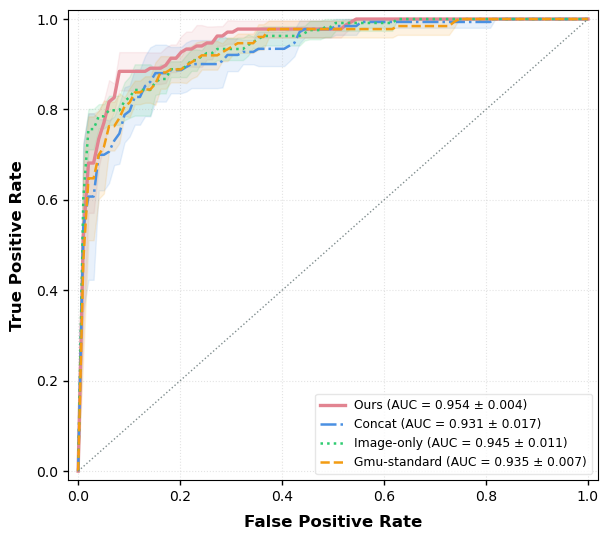

Saved multi-model ROC to roc_multi.svg


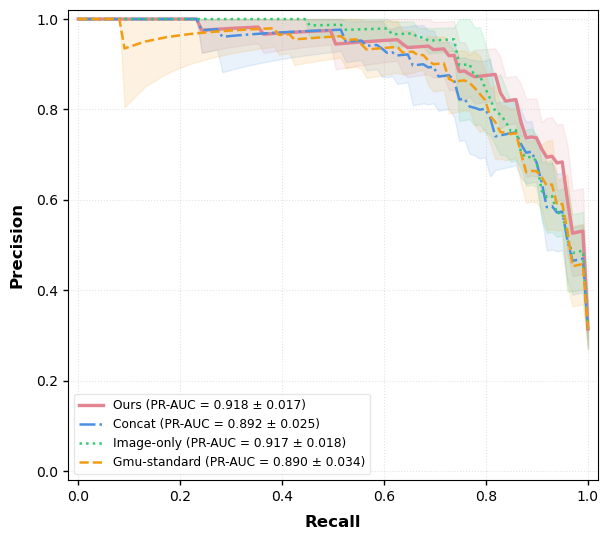

Saved multi-model PR to pr_multi.svg


In [35]:
import torch
import pickle

def load_data(pkl_path):
    try:
        data = torch.load(pkl_path, map_location='cpu', weights_only=False)
    except Exception:
        with open(pkl_path, 'rb') as f:
            data = pickle.load(f)
    return data['fold_results'] if isinstance(data, dict) and 'fold_results' in data else data

# 准备传入 results_list
results_list = [
    {'model_name': 'MedicalGMU', 'fold_results': load_data('./experiments/gmu_asymmetric/predictions/5fold_results.pkl')},
    {'model_name': 'Concat',     'fold_results': load_data('./experiments/concat/predictions/5fold_results.pkl')},
    {'model_name': 'Image-only', 'fold_results': load_data('./experiments/image_only/predictions/5fold_results.pkl')},
    {'model_name': 'Gmu-standard',   'fold_results': load_data('./experiments/gmu_standard/predictions/5fold_results.pkl')},
]

# 一键出图
plot_roc_curves_multi(results_list, save_path='roc_multi.svg')
plot_pr_curves_multi(results_list, save_path='pr_multi.svg')

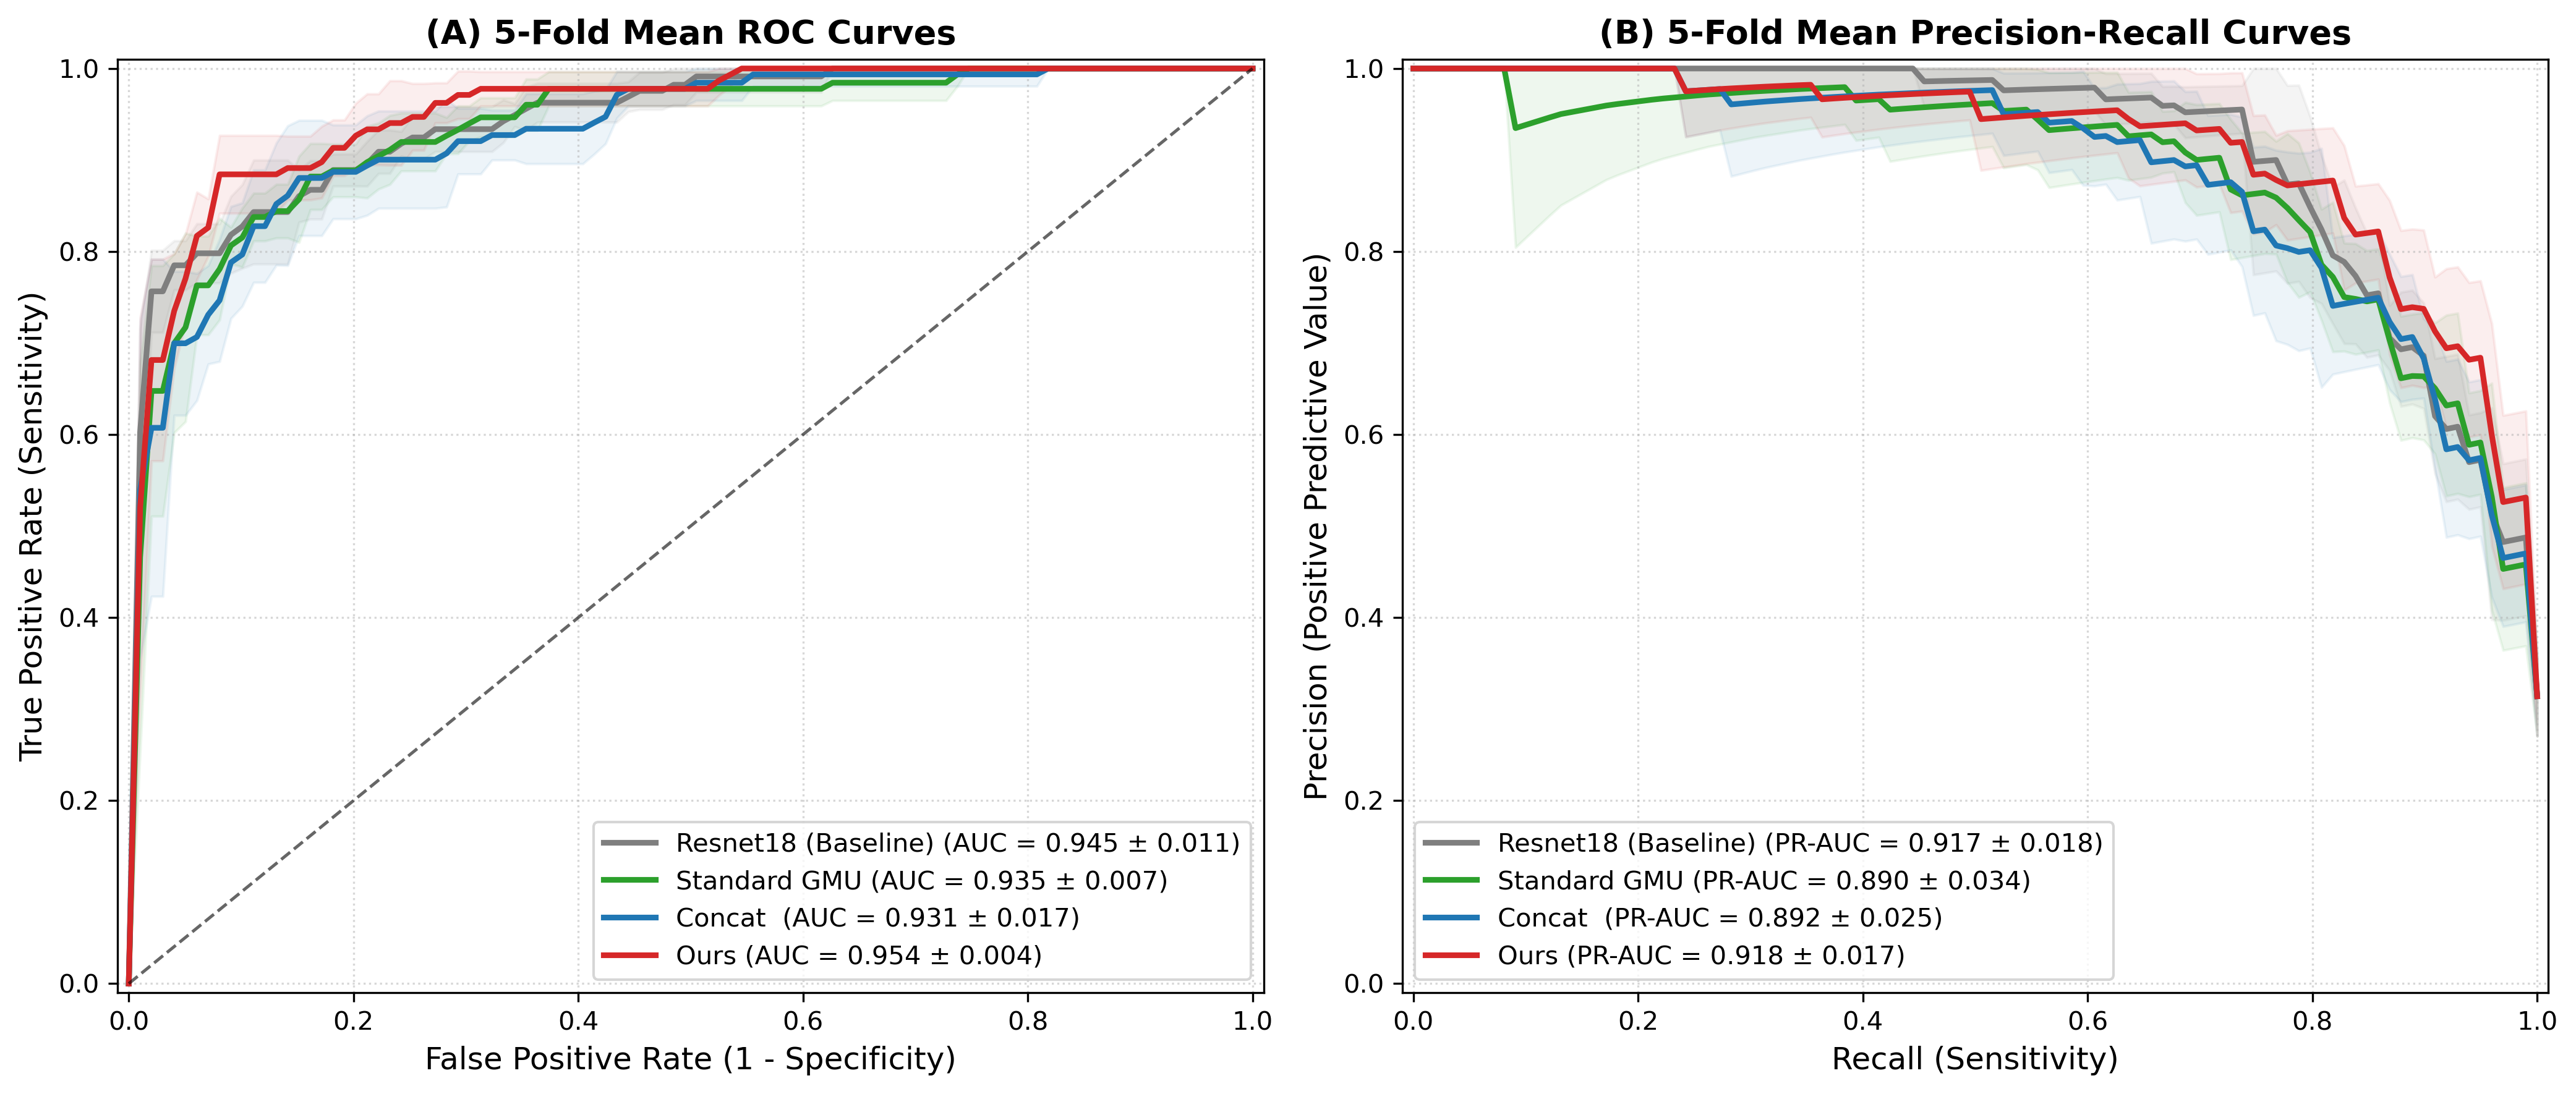

In [25]:
# ──────────────── 3. 配置你的模型路径 ────────────────
# 替换为你的 4 个实验目录下的 5fold_results.pkl 实际路径
# model_paths = {
#     'Image-only': './experiments/image_only/predictions/5fold_results.pkl',
#     'Clinical-only': './experiments/clinical_only/predictions/5fold_results.pkl',
#     'Concat': './experiments/concat/predictions/5fold_results.pkl',
#     'Ours (GMU/Proposed)': './experiments/ours/predictions/5fold_results.pkl',
# }
model_paths = {
    'Resnet18 (Baseline)': './experiments/image_only/predictions/5fold_results.pkl',
    'Standard GMU': './experiments/gmu_standard/predictions/5fold_results.pkl',
    'Concat ': './experiments/concat/predictions/5fold_results.pkl',
    'Ours': './experiments/gmu_asymmetric/predictions/5fold_results.pkl'
}
# 顶刊配色：灰色、绿色、蓝色、红色
colors = ['#7f7f7f', '#2ca02c', '#1f77b4', '#d62728']

# ──────────────── 4. 左右双子图联合绘制 ────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=300)

for (model_name, pkl_path), color in zip(model_paths.items(), colors):
    fold_dict = load_fold_data_from_5fold_pkl(pkl_path)
    
    # ── (1) 计算并绘制 ROC ──
    fpr, tpr, std_tpr, mean_auc, std_auc = compute_5fold_mean_roc(fold_dict)
    axes[0].plot(
        fpr, tpr, color=color, lw=2.2,
        label=f'{model_name} (AUC = {mean_auc:.3f} ± {std_auc:.3f})'
    )
    # ±1 Std 阴影带
    axes[0].fill_between(
        fpr,
        np.maximum(tpr - std_tpr, 0),
        np.minimum(tpr + std_tpr, 1),
        color=color, alpha=0.08
    )

    # ── (2) 计算并绘制 PR ──
    rec, prec, std_prec, mean_ap, std_ap = compute_5fold_mean_pr(fold_dict)
    axes[1].plot(
        rec, prec, color=color, lw=2.2,
        label=f'{model_name} (PR-AUC = {mean_ap:.3f} ± {std_ap:.3f})'
    )
    # ±1 Std 阴影带
    axes[1].fill_between(
        rec,
        np.maximum(prec - std_prec, 0),
        np.minimum(prec + std_prec, 1),
        color=color, alpha=0.08
    )

# ── ROC 子图样式 ──
axes[0].plot([0, 1], [0, 1], 'k--', lw=1.2, alpha=0.6)
axes[0].set_xlim([-0.01, 1.01])
axes[0].set_ylim([-0.01, 1.01])
axes[0].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
axes[0].set_ylabel('True Positive Rate (Sensitivity)', fontsize=12)
axes[0].set_title('(A) 5-Fold Mean ROC Curves', fontsize=13, fontweight='bold')
axes[0].legend(loc='lower right', frameon=True, fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.5)

# ── PR 子图样式 ──
axes[1].set_xlim([-0.01, 1.01])
axes[1].set_ylim([-0.01, 1.01])
axes[1].set_xlabel('Recall (Sensitivity)', fontsize=12)
axes[1].set_ylabel('Precision (Positive Predictive Value)', fontsize=12)
axes[1].set_title('(B) 5-Fold Mean Precision-Recall Curves', fontsize=13, fontweight='bold')
axes[1].legend(loc='lower left', frameon=True, fontsize=10)
axes[1].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig('5fold_comparison_curves.pdf', format='pdf', bbox_inches='tight')
plt.savefig('5fold_comparison_curves.svg', format='svg', bbox_inches='tight')
plt.show()

# p值

In [38]:
import numpy as np
import scipy.stats as stats

# ==========================================
# 1. DeLong's Test (用于对比两个模型的 ROC-AUC)
# ==========================================
def compute_midrank(x):
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + 1 + j)
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2

def fast_delong(predictions_sorted_transposed, label_1_count):
    m = label_1_count
    n = predictions_sorted_transposed.shape[1] - m
    positive_examples = predictions_sorted_transposed[:, :m]
    negative_examples = predictions_sorted_transposed[:, m:]
    k = predictions_sorted_transposed.shape[0]

    tx = np.empty([k, m], dtype=float)
    ty = np.empty([k, n], dtype=float)
    tz = np.empty([k, m + n], dtype=float)
    for r in range(k):
        tx[r, :] = compute_midrank(positive_examples[r, :])
        ty[r, :] = compute_midrank(negative_examples[r, :])
        tz[r, :] = compute_midrank(predictions_sorted_transposed[r, :])

    total_auc = (np.sum(tz[:, :m], axis=1) - m * (m + 1) / 2) / (m * n)
    v01 = (tz[:, :m] - tx[:, :]) / n
    v10 = 1.0 - (tz[:, m:] - ty[:, :]) / m

    sx = np.cov(v01)
    sy = np.cov(v10)
    delongcov = sx / m + sy / n
    return total_auc, delongcov

def delong_roc_test(ground_truth, preds_A, preds_B):
    """
    计算两组预测概率的 AUC 差异及 DeLong p 值
    """
    ground_truth = np.asarray(ground_truth)
    preds_A = np.asarray(preds_A)
    preds_B = np.asarray(preds_B)

    # 按真值排序：先排列 1，再排列 0
    order = np.argsort(ground_truth)[::-1]
    y = ground_truth[order]
    m = int(np.sum(y == 1))

    preds = np.vstack([preds_A[order], preds_B[order]])
    aucs, sigma = fast_delong(preds, m)

    # 统计量 Z 与双尾 p 值
    diff = aucs[0] - aucs[1]
    var = sigma[0, 0] + sigma[1, 1] - 2 * sigma[0, 1]
    if var <= 0:
        return aucs[0], aucs[1], 1.0
    z = diff / np.sqrt(var)
    p_value = 2 * (1 - stats.norm.cdf(np.abs(z)))
    return aucs[0], aucs[1], p_value


# ==========================================================
# 2. McNemar's Test (用于对比 Sensitivity 与 Specificity)
# ==========================================================
def mcnemar_test_paired(y_true, y_pred_A, y_pred_B, subset_label=None):
    """
    配对样本 McNemar 检验（小样本采用精确二项分布检验，大样本带连续性修正）
    - subset_label=1: 检验 Sensitivity 的差异
    - subset_label=0: 检验 Specificity 的差异
    - subset_label=None: 检验 Overall Accuracy 的差异
    """
    y_true = np.asarray(y_true)
    pred_A = np.asarray(y_pred_A)
    pred_B = np.asarray(y_pred_B)

    # 筛选子集
    if subset_label is not None:
        mask = (y_true == subset_label)
        y_true = y_true[mask]
        pred_A = pred_A[mask]
        pred_B = pred_B[mask]

    # 正确性标记 (布尔向量: 预测是否正确)
    correct_A = (pred_A == y_true)
    correct_B = (pred_B == y_true)

    # 2x2 列联表中的非对角线元素:
    # b: A 对但 B 错
    # c: A 错但 B 对
    b = np.sum(correct_A & (~correct_B))
    c = np.sum((~correct_A) & correct_B)

    if b + c == 0:
        return 1.0  # 两模型完全一致，无差异

    # 若不一致样本较少 (< 25)，采用精确二项检验；否则采用带修正的卡方
    if b + c < 25:
        res = stats.binomtest(min(b, c), b + c, 0.5, alternative='two-sided')
        p_val = res.pvalue
    else:
        chi2 = (np.abs(b - c) - 1.0) ** 2 / (b + c)
        p_val = 1 - stats.chi2.cdf(chi2, df=1)

    return p_val

## 运行

In [39]:
import pickle
import torch
import pandas as pd

def load_data(pkl_path):
    try:
        data = torch.load(pkl_path, map_location='cpu', weights_only=False)
    except Exception:
        with open(pkl_path, 'rb') as f:
            data = pickle.load(f)
    if isinstance(data, dict) and 'fold_results' in data:
        data = data['fold_results']
    
    # 拼接全部 5 折样本，恢复全局配对序列
    labels = np.concatenate([v[0] for v in data.values()])
    probs = np.concatenate([v[1] for v in data.values()])
    return labels, probs

# 设定模型路径
model_files = {
    'Ours (MedicalGMU)':      './experiments/gmu_asymmetric/predictions/5fold_results.pkl',
    'Concat':          './experiments/concat/predictions/5fold_results.pkl',
    'Image-only':      './experiments/image_only/predictions/5fold_results.pkl',
    'Gmu-standard':   './experiments/gmu_standard/predictions/5fold_results.pkl'
}


# 加载数据并生成二值化预测 (阈值可按配置设为 0.5)
threshold = 0.25
preds_dict = {}
for name, p in model_files.items():
    lbl, pr = load_data(p)
    preds_dict[name] = {
        'probs': pr,
        'preds': (pr >= threshold).astype(int),
        'labels': lbl
    }

# 基准模型与对照组
target_model = 'Ours (MedicalGMU)'
y_true = preds_dict[target_model]['labels']
our_probs = preds_dict[target_model]['probs']
our_preds = preds_dict[target_model]['preds']

# 计算各模型与 Ours 的显著性 p 值
table_rows = []
for m_name in model_files.keys():
    pr = preds_dict[m_name]['probs']
    pd_cls = preds_dict[m_name]['preds']
    
    # 1. 计算指标点估计
    sens = np.mean(pd_cls[y_true == 1] == 1)
    spec = np.mean(pd_cls[y_true == 0] == 0)
    
    # 2. 计算 p 值 (对比 Ours)
    if m_name == target_model:
        auc_pval = "-"
        sens_pval = "-"
        spec_pval = "-"
        auc_val = stats.roc_auc_score(y_true, pr)
    else:
        _, auc_val, auc_pval_num = delong_roc_test(y_true, our_probs, pr)
        auc_pval = f"{auc_pval_num:.4f}" if auc_pval_num >= 0.001 else "<0.001"
        
        # Sensitivity p-value (subset_label=1)
        s_pval_num = mcnemar_test_paired(y_true, our_preds, pd_cls, subset_label=1)
        sens_pval = f"{s_pval_num:.4f}" if s_pval_num >= 0.001 else "<0.001"
        
        # Specificity p-value (subset_label=0)
        sp_pval_num = mcnemar_test_paired(y_true, our_preds, pd_cls, subset_label=0)
        spec_pval = f"{sp_pval_num:.4f}" if sp_pval_num >= 0.001 else "<0.001"

    table_rows.append({
        'Model': m_name,
        'AUC': f"{auc_val:.3f}",
        'AUC p-val': auc_pval,
        'Sensitivity': f"{sens:.3f}",
        'Sens p-val': sens_pval,
        'Specificity': f"{spec:.3f}",
        'Spec p-val': spec_pval
    })

df_significance = pd.DataFrame(table_rows)
print(df_significance.to_string(index=False))

AttributeError: module 'scipy.stats' has no attribute 'roc_auc_score'

In [40]:
import pickle
import torch
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.metrics import roc_auc_score


# ==========================================================
# 1. 统计检验核心算法定义 (DeLong's Test & McNemar's Test)
# ==========================================================
def compute_midrank(x):
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + 1 + j)
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2

def fast_delong(predictions_sorted_transposed, label_1_count):
    m = label_1_count
    n = predictions_sorted_transposed.shape[1] - m
    positive_examples = predictions_sorted_transposed[:, :m]
    negative_examples = predictions_sorted_transposed[:, m:]
    k = predictions_sorted_transposed.shape[0]

    tx = np.empty([k, m], dtype=float)
    ty = np.empty([k, n], dtype=float)
    tz = np.empty([k, m + n], dtype=float)
    for r in range(k):
        tx[r, :] = compute_midrank(positive_examples[r, :])
        ty[r, :] = compute_midrank(negative_examples[r, :])
        tz[r, :] = compute_midrank(predictions_sorted_transposed[r, :])

    total_auc = (np.sum(tz[:, :m], axis=1) - m * (m + 1) / 2) / (m * n)
    v01 = (tz[:, :m] - tx[:, :]) / n
    v10 = 1.0 - (tz[:, m:] - ty[:, :]) / m

    sx = np.cov(v01)
    sy = np.cov(v10)
    delongcov = sx / m + sy / n
    return total_auc, delongcov

def delong_roc_test(ground_truth, preds_A, preds_B):
    ground_truth = np.asarray(ground_truth).ravel()
    preds_A = np.asarray(preds_A).ravel()
    preds_B = np.asarray(preds_B).ravel()

    order = np.argsort(ground_truth)[::-1]
    y = ground_truth[order]
    m = int(np.sum(y == 1))

    preds = np.vstack([preds_A[order], preds_B[order]])
    aucs, sigma = fast_delong(preds, m)

    diff = aucs[0] - aucs[1]
    var = sigma[0, 0] + sigma[1, 1] - 2 * sigma[0, 1]
    if var <= 0:
        return aucs[0], aucs[1], 1.0
    z = diff / np.sqrt(var)
    p_value = 2 * (1 - stats.norm.cdf(np.abs(z)))
    return aucs[0], aucs[1], p_value

def mcnemar_test_paired(y_true, y_pred_A, y_pred_B, subset_label=None):
    y_true = np.asarray(y_true).ravel()
    pred_A = np.asarray(y_pred_A).ravel()
    pred_B = np.asarray(y_pred_B).ravel()

    if subset_label is not None:
        mask = (y_true == subset_label)
        y_true = y_true[mask]
        pred_A = pred_A[mask]
        pred_B = pred_B[mask]

    correct_A = (pred_A == y_true)
    correct_B = (pred_B == y_true)

    b = np.sum(correct_A & (~correct_B))
    c = np.sum((~correct_A) & correct_B)

    if b + c == 0:
        return 1.0

    if b + c < 25:
        res = stats.binomtest(min(b, c), b + c, 0.5, alternative='two-sided')
        return res.pvalue
    else:
        chi2 = (np.abs(b - c) - 1.0) ** 2 / (b + c)
        return 1 - stats.chi2.cdf(chi2, df=1)


# ==========================================================
# 2. 数据读取与评估流程
# ==========================================================
def to_numpy(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    return np.asarray(x)

def load_data(pkl_path):
    try:
        data = torch.load(pkl_path, map_location='cpu', weights_only=False)
    except Exception:
        with open(pkl_path, 'rb') as f:
            data = pickle.load(f)
    if isinstance(data, dict) and 'fold_results' in data:
        data = data['fold_results']

    # 显式转为 1D numpy array，防止类型不兼容
    labels = np.concatenate([to_numpy(v[0]).ravel() for v in data.values()])
    probs = np.concatenate([to_numpy(v[1]).ravel() for v in data.values()])
    return labels, probs

# 设定模型路径
model_files = {
    'Ours (MedicalGMU)': './experiments/gmu_asymmetric/predictions/5fold_results.pkl',
    'Concat':            './experiments/concat/predictions/5fold_results.pkl',
    'Image-only':        './experiments/image_only/predictions/5fold_results.pkl',
    'Gmu-standard':      './experiments/gmu_standard/predictions/5fold_results.pkl'
}

threshold = 0.25
preds_dict = {}

for name, p in model_files.items():
    lbl, pr = load_data(p)
    preds_dict[name] = {
        'probs': pr,
        'preds': (pr >= threshold).astype(int),
        'labels': lbl.astype(int)
    }

target_model = 'Ours (MedicalGMU)'
y_true = preds_dict[target_model]['labels']
our_probs = preds_dict[target_model]['probs']
our_preds = preds_dict[target_model]['preds']

table_rows = []
for m_name in model_files.keys():
    pr = preds_dict[m_name]['probs']
    pd_cls = preds_dict[m_name]['preds']

    # 1. 计算指标点估计
    sens = np.mean(pd_cls[y_true == 1] == 1)
    spec = np.mean(pd_cls[y_true == 0] == 0)

    # 2. 计算 p 值 (对比 Ours)
    if m_name == target_model:
        auc_pval = "-"
        sens_pval = "-"
        spec_pval = "-"
        auc_val = roc_auc_score(y_true, pr)  # 修复：正确调用 sklearn 的 roc_auc_score
    else:
        _, auc_val, auc_pval_num = delong_roc_test(y_true, our_probs, pr)
        auc_pval = f"{auc_pval_num:.4f}" if auc_pval_num >= 0.001 else "<0.001"

        # Sensitivity p 值 (只看真实阳性 y=1)
        s_pval_num = mcnemar_test_paired(y_true, our_preds, pd_cls, subset_label=1)
        sens_pval = f"{s_pval_num:.4f}" if s_pval_num >= 0.001 else "<0.001"

        # Specificity p 值 (只看真实阴性 y=0)
        sp_pval_num = mcnemar_test_paired(y_true, our_preds, pd_cls, subset_label=0)
        spec_pval = f"{sp_pval_num:.4f}" if sp_pval_num >= 0.001 else "<0.001"

    table_rows.append({
        'Model': m_name,
        'AUC': f"{auc_val:.3f}",
        'AUC p-val': auc_pval,
        'Sensitivity': f"{sens:.3f}",
        'Sens p-val': sens_pval,
        'Specificity': f"{spec:.3f}",
        'Spec p-val': spec_pval
    })

df_significance = pd.DataFrame(table_rows)
print(df_significance.to_string(index=False))

            Model   AUC AUC p-val Sensitivity Sens p-val Specificity Spec p-val
Ours (MedicalGMU) 0.952         -       0.941          -       0.773          -
           Concat 0.926    0.0240       0.837     <0.001       0.847     <0.001
       Image-only 0.940    0.2682       0.889     0.0923       0.793     0.4404
     Gmu-standard 0.909    <0.001       0.785     <0.001       0.858     <0.001


In [1]:
import pickle
import torch
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    accuracy_score, confusion_matrix
)

# ==========================================================
# 1. 统计检验核心函数 (DeLong + McNemar + Paired Bootstrap)
# ==========================================================
def compute_midrank(x):
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + 1 + j)
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2

def fast_delong(predictions_sorted_transposed, label_1_count):
    m = label_1_count
    n = predictions_sorted_transposed.shape[1] - m
    positive_examples = predictions_sorted_transposed[:, :m]
    negative_examples = predictions_sorted_transposed[:, m:]
    k = predictions_sorted_transposed.shape[0]

    tx = np.empty([k, m], dtype=float)
    ty = np.empty([k, n], dtype=float)
    tz = np.empty([k, m + n], dtype=float)
    for r in range(k):
        tx[r, :] = compute_midrank(positive_examples[r, :])
        ty[r, :] = compute_midrank(negative_examples[r, :])
        tz[r, :] = compute_midrank(predictions_sorted_transposed[r, :])

    total_auc = (np.sum(tz[:, :m], axis=1) - m * (m + 1) / 2) / (m * n)
    v01 = (tz[:, :m] - tx[:, :]) / n
    v10 = 1.0 - (tz[:, m:] - ty[:, :]) / m

    sx = np.cov(v01)
    sy = np.cov(v10)
    delongcov = sx / m + sy / n
    return total_auc, delongcov

def delong_roc_test(ground_truth, preds_A, preds_B):
    """DeLong's Test: 检验两个模型的 ROC-AUC 差异"""
    ground_truth = np.asarray(ground_truth).ravel()
    preds_A = np.asarray(preds_A).ravel()
    preds_B = np.asarray(preds_B).ravel()

    order = np.argsort(ground_truth)[::-1]
    y = ground_truth[order]
    m = int(np.sum(y == 1))

    preds = np.vstack([preds_A[order], preds_B[order]])
    aucs, sigma = fast_delong(preds, m)

    diff = aucs[0] - aucs[1]
    var = sigma[0, 0] + sigma[1, 1] - 2 * sigma[0, 1]
    if var <= 0:
        return 1.0
    z = diff / np.sqrt(var)
    p_value = 2 * (1 - stats.norm.cdf(np.abs(z)))
    return float(p_value)

def mcnemar_test_paired(y_true, y_pred_A, y_pred_B, subset_label=None):
    """
    配对 McNemar 检验:
    - subset_label=1: 检验 Sensitivity
    - subset_label=0: 检验 Specificity
    - subset_label=None: 检验 ACC (Accuracy)
    """
    y_true = np.asarray(y_true).ravel()
    pred_A = np.asarray(y_pred_A).ravel()
    pred_B = np.asarray(y_pred_B).ravel()

    if subset_label is not None:
        mask = (y_true == subset_label)
        y_true = y_true[mask]
        pred_A = pred_A[mask]
        pred_B = pred_B[mask]

    correct_A = (pred_A == y_true)
    correct_B = (pred_B == y_true)

    b = int(np.sum(correct_A & (~correct_B)))
    c = int(np.sum((~correct_A) & correct_B))

    if b + c == 0:
        return 1.0

    if b + c < 25:
        res = stats.binomtest(min(b, c), b + c, 0.5, alternative='two-sided')
        return float(res.pvalue)
    else:
        chi2 = (np.abs(b - c) - 1.0) ** 2 / (b + c)
        return float(1 - stats.chi2.cdf(chi2, df=1))

def paired_bootstrap_test(y_true, vals_A, vals_B, metric_fn, n_bootstraps=2000, seed=42):
    """
    配对 Bootstrap 检验: 用于检验 AU-PRC (AP) 和 F1-score 的显著性差异
    """
    rng = np.random.RandomState(seed)
    y_true = np.asarray(y_true).ravel()
    vals_A = np.asarray(vals_A).ravel()
    vals_B = np.asarray(vals_B).ravel()
    N = len(y_true)

    obs_diff = metric_fn(y_true, vals_A) - metric_fn(y_true, vals_B)
    boot_diffs = []

    for _ in range(n_bootstraps):
        idx = rng.randint(0, N, N)
        # 确保重采样集中包含正负两类样本
        if len(np.unique(y_true[idx])) < 2:
            continue
        diff = metric_fn(y_true[idx], vals_A[idx]) - metric_fn(y_true[idx], vals_B[idx])
        boot_diffs.append(diff)

    boot_diffs = np.asarray(boot_diffs)
    # 中心化零假设分布 (Shift to null hypothesis H0: diff = 0)
    centered_diffs = boot_diffs - np.mean(boot_diffs)
    p_val = np.mean(np.abs(centered_diffs) >= np.abs(obs_diff))
    return float(p_val)

def format_pval(p):
    if p == "-":
        return "-"
    return f"{p:.4f}" if p >= 0.001 else "<0.001"


# ==========================================================
# 2. 数据加载、严格配对对齐与 5-Fold 指标计算
# ==========================================================
def to_numpy(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    return np.asarray(x)

def evaluate_model_5fold(pkl_path, threshold=0.25):
    """
    读取单个模型的 5fold_results.pkl：
    1. 逐折计算 6 大指标，返回 5 折均值与标准差
    2. 按 (fold_idx, joint_id) 严格排序拼接 OOF 预测，用于配对 p 值检验
    """
    try:
        data = torch.load(pkl_path, map_location='cpu', weights_only=False)
    except Exception:
        with open(pkl_path, 'rb') as f:
            data = pickle.load(f)

    fold_dict = data['fold_results'] if isinstance(data, dict) and 'fold_results' in data else data

    fold_metrics = {
        'AUC-ROC': [], 'AU-PRC': [], 'F1': [],
        'Specificity': [], 'Sensitivity': [], 'ACC': []
    }

    oof_labels, oof_probs, oof_preds, oof_ids = [], [], [], []

    # 严格按 fold_idx 升序遍历
    for fold_idx in sorted(fold_dict.keys()):
        item = fold_dict[fold_idx]
        y_true = to_numpy(item[0]).ravel().astype(int)
        y_prob = to_numpy(item[1]).ravel().astype(float)

        # 如果保存了 joint_ids (第3项)，按 joint_id 排序保证跨模型 100% 配对对齐
        if len(item) >= 3 and item[2] is not None:
            jids = [f"F{fold_idx}_{jid}" for jid in item[2]]
            sort_idx = np.argsort(jids)
            y_true = y_true[sort_idx]
            y_prob = y_prob[sort_idx]
            jids = [jids[i] for i in sort_idx]
        else:
            jids = [f"F{fold_idx}_{i}" for i in range(len(y_true))]

        y_pred = (y_prob >= threshold).astype(int)

        # 计算单折 6 大指标
        auc_roc = roc_auc_score(y_true, y_prob)
        au_prc = average_precision_score(y_true, y_prob)
        f1 = f1_score(y_true, y_pred, zero_division=0)
        acc = accuracy_score(y_true, y_pred)
        tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
        sens = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0

        fold_metrics['AUC-ROC'].append(auc_roc)
        fold_metrics['AU-PRC'].append(au_prc)
        fold_metrics['F1'].append(f1)
        fold_metrics['Specificity'].append(spec)
        fold_metrics['Sensitivity'].append(sens)
        fold_metrics['ACC'].append(acc)

        oof_labels.append(y_true)
        oof_probs.append(y_prob)
        oof_preds.append(y_pred)
        oof_ids.extend(jids)

    return {
        'fold_metrics': fold_metrics,
        'oof_labels': np.concatenate(oof_labels),
        'oof_probs': np.concatenate(oof_probs),
        'oof_preds': np.concatenate(oof_preds),
        'oof_ids': oof_ids
    }


# ==========================================================
# 3. 主流程：汇总 4 个模型的 5-Fold 均值±标准差 与 显著性 p 值
# ==========================================================
model_files = {
    'Ours (MedicalGMU)': './experiments/gmu_asymmetric/predictions/5fold_results.pkl',
    'Concat':            './experiments/concat/predictions/5fold_results.pkl',
    'Image-only':        './experiments/image_only/predictions/5fold_results.pkl',
    'Gmu-standard':      './experiments/gmu_standard/predictions/5fold_results.pkl'
}

THRESHOLD = 0.25
target_model = 'Ours (MedicalGMU)'

parsed_models = {}
for name, path in model_files.items():
    parsed_models[name] = evaluate_model_5fold(path, threshold=THRESHOLD)

# 基准模型 OOF 数据
ref = parsed_models[target_model]
y_true_ref = ref['oof_labels']

summary_rows = []
pvalue_rows = []

metric_names = ['AUC-ROC', 'AU-PRC', 'F1', 'Specificity', 'Sensitivity', 'ACC']

for m_name in model_files.keys():
    curr = parsed_models[m_name]
    fm = curr['fold_metrics']

    # 强制校验跨模型样本配对一致性！防止顺序错位
    assert np.array_equal(y_true_ref, curr['oof_labels']), (
        f"[错误] 模型 {m_name} 与 {target_model} 的样本标签顺序不一致，无法直接做配对检验！"
    )

    # 1. 组装 5-Fold Mean ± Std 汇总行
    row_metric = {'Model': m_name}
    for k in metric_names:
        mean_val = np.mean(fm[k])
        std_val = np.std(fm[k])
        row_metric[k] = f"{mean_val:.3f} ± {std_val:.3f}"
    summary_rows.append(row_metric)

    # 2. 计算与 Ours 的配对 p 值
    if m_name == target_model:
        pvalue_rows.append({
            'Model': m_name,
            'AUC-ROC p-val': '-',
            'AU-PRC p-val':  '-',
            'F1 p-val':      '-',
            'Spec p-val':    '-',
            'Sens p-val':    '-',
            'ACC p-val':     '-'
        })
    else:
        p_auc = delong_roc_test(y_true_ref, ref['oof_probs'], curr['oof_probs'])
        p_prc = paired_bootstrap_test(
            y_true_ref, ref['oof_probs'], curr['oof_probs'],
            metric_fn=average_precision_score, n_bootstraps=2000
        )
        p_f1 = paired_bootstrap_test(
            y_true_ref, ref['oof_preds'], curr['oof_preds'],
            metric_fn=lambda y, p: f1_score(y, p, zero_division=0), n_bootstraps=2000
        )
        p_spec = mcnemar_test_paired(y_true_ref, ref['oof_preds'], curr['oof_preds'], subset_label=0)
        p_sens = mcnemar_test_paired(y_true_ref, ref['oof_preds'], curr['oof_preds'], subset_label=1)
        p_acc  = mcnemar_test_paired(y_true_ref, ref['oof_preds'], curr['oof_preds'], subset_label=None)

        pvalue_rows.append({
            'Model': m_name,
            'AUC-ROC p-val': format_pval(p_auc),
            'AU-PRC p-val':  format_pval(p_prc),
            'F1 p-val':      format_pval(p_f1),
            'Spec p-val':    format_pval(p_spec),
            'Sens p-val':    format_pval(p_sens),
            'ACC p-val':     format_pval(p_acc)
        })

df_metrics = pd.DataFrame(summary_rows)
df_pvals = pd.DataFrame(pvalue_rows)

print("=" * 95)
print(f"表 1: 4 个模型 5-Fold 交叉验证性能对比 (Mean ± Std, Threshold = {THRESHOLD})")
print("=" * 95)
print(df_metrics.to_string(index=False))

print("\n" + "=" * 95)
print(f"表 2: 与 {target_model} 对比的配对统计显著性检验 (p-values)")
print("注: AUC-ROC 采用 DeLong 检验; AU-PRC 与 F1 采用 Paired Bootstrap (B=2000); Spec/Sens/ACC 采用配对 McNemar 检验")
print("=" * 95)
print(df_pvals.to_string(index=False))

表 1: 4 个模型 5-Fold 交叉验证性能对比 (Mean ± Std, Threshold = 0.25)
            Model       AUC-ROC        AU-PRC            F1   Specificity   Sensitivity           ACC
Ours (MedicalGMU) 0.954 ± 0.004 0.918 ± 0.017 0.770 ± 0.037 0.772 ± 0.038 0.940 ± 0.019 0.826 ± 0.024
           Concat 0.931 ± 0.017 0.892 ± 0.025 0.772 ± 0.039 0.846 ± 0.057 0.838 ± 0.072 0.844 ± 0.038
       Image-only 0.945 ± 0.011 0.917 ± 0.018 0.757 ± 0.027 0.790 ± 0.064 0.883 ± 0.076 0.823 ± 0.026
     Gmu-standard 0.935 ± 0.007 0.890 ± 0.034 0.752 ± 0.051 0.860 ± 0.117 0.789 ± 0.119 0.835 ± 0.052

表 2: 与 Ours (MedicalGMU) 对比的配对统计显著性检验 (p-values)
注: AUC-ROC 采用 DeLong 检验; AU-PRC 与 F1 采用 Paired Bootstrap (B=2000); Spec/Sens/ACC 采用配对 McNemar 检验
            Model AUC-ROC p-val AU-PRC p-val F1 p-val Spec p-val Sens p-val ACC p-val
Ours (MedicalGMU)             -            -        -          -          -         -
           Concat        0.0240       0.0895   0.9695     <0.001     <0.001    0.3317
       Image-only        0.